PERFORMING EDA

In [1]:
#imports
import pandas as pd
import numpy as np
df = pd.read_csv("events.csv")

In [14]:
df.shape

(885129, 9)

In [15]:
df.columns 


Index(['event_time', 'event_type', 'product_id', 'category_id',
       'category_code', 'brand', 'price', 'user_id', 'user_session'],
      dtype='str')

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 885129 entries, 0 to 885128
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     885129 non-null  str    
 1   event_type     885129 non-null  str    
 2   product_id     885129 non-null  int64  
 3   category_id    885129 non-null  int64  
 4   category_code  648910 non-null  str    
 5   brand          672765 non-null  str    
 6   price          885129 non-null  float64
 7   user_id        885129 non-null  int64  
 8   user_session   884964 non-null  str    
dtypes: float64(1), int64(3), str(5)
memory usage: 112.2 MB


In [17]:
df.isnull().sum() #Reason for missing values? 

event_time            0
event_type            0
product_id            0
category_id           0
category_code    236219
brand            212364
price                 0
user_id               0
user_session        165
dtype: int64

In [ ]:
df.duplicated().sum() 

np.int64(655)

In [11]:
duplicates = df[df.duplicated(keep=False)]

duplicates.sort_values(
    by=["user_id", "user_session", "event_time"]
).head(20)

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,hour
135997,2020-10-22 18:32:04+00:00,view,478724,2144415924491387038,computers.components.motherboard,asus,52.90,1515915625367766093,r5QKrUaDgr,18
135998,2020-10-22 18:32:04+00:00,view,478724,2144415924491387038,computers.components.motherboard,asus,52.90,1515915625367766093,r5QKrUaDgr,18
132075,2020-10-22 07:46:41+00:00,view,622757,2144415926848585945,NaN,NaN,102.16,1515915625373342675,obu3k5f27J,7
132076,2020-10-22 07:46:41+00:00,view,622757,2144415926848585945,NaN,NaN,102.16,1515915625373342675,obu3k5f27J,7
53101,2020-10-06 12:58:49+00:00,view,4099841,2144415922125799520,NaN,palmexx,56.67,1515915625388149041,ZlIip8HCO3,12
53102,2020-10-06 12:58:49+00:00,view,4099841,2144415922125799520,NaN,palmexx,56.67,1515915625388149041,ZlIip8HCO3,12
36875,2020-10-02 20:32:16+00:00,view,4079447,2144415926848585945,NaN,nzxt,158.17,1515915625424957684,7TcCWAT6S9,20
36876,2020-10-02 20:32:16+00:00,view,4079447,2144415926848585945,NaN,nzxt,158.17,1515915625424957684,7TcCWAT6S9,20
45272,2020-10-04 21:04:09+00:00,view,4078407,2144415926966026460,computers.components.cpu,amd,365.38,1515915625453727914,28821430-fbaf-4c08-8e7a-ac7fa3307b47,21
45273,2020-10-04 21:04:09+00:00,view,4078407,2144415926966026460,computers.components.cpu,amd,365.38,1515915625453727914,28821430-fbaf-4c08-8e7a-ac7fa3307b47,21


In [12]:
df = df.drop_duplicates()

In [13]:
df.duplicated().sum()

np.int64(0)

### Duplicate Records

I found 655 completely duplicated rows in the dataset. After checking some of these records, I found that the same user, session, product, event type and timestamp were repeated exactly. Since these appeared to be duplicate event records rather than separate customer actions, I removed the exact duplicates.

In [14]:
df['event_type'].value_counts()

event_type
view        793099
cart         54032
purchase     37343
Name: count, dtype: int64

In [21]:
df['event_type'].value_counts(normalize=True) * 100

event_type
view        89.675968
cart         6.104760
purchase     4.219272
Name: proportion, dtype: float64

In [22]:
df['price'].describe()

count    885129.000000
mean        146.328713
std         296.807683
min           0.220000
25%          26.460000
50%          65.710000
75%         190.490000
max       64771.060000
Name: price, dtype: float64

In [23]:
df['user_id'].nunique()

407283

In [24]:
df['user_id'].value_counts().describe()

count    407283.000000
mean          2.173253
std           4.409694
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max         572.000000
Name: count, dtype: float64

In [25]:
df['price'].max()

np.float64(64771.06)

In [26]:
df['price'].min()

np.float64(0.22)

### Price Distribution

The dataset contains some very high-priced products, which makes the full price distribution difficult to read. For this visualization, I have focused on prices below 5000 to better understand the distribution of the majority of product events.

The original data was not removed or changed; this filter was only used for visualization.

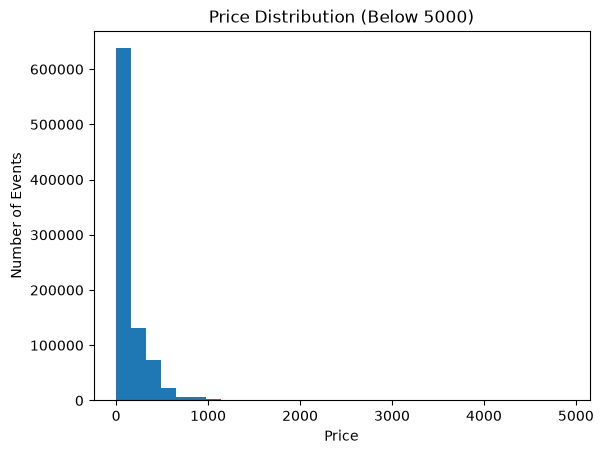

In [8]:
import matplotlib.pyplot as plt

normal_prices = df[df["price"] < 5000]

normal_prices["price"].plot(kind="hist", bins=30)

plt.title("Price Distribution (Below 5000)")
plt.xlabel("Price")
plt.ylabel("Number of Events")
plt.show()

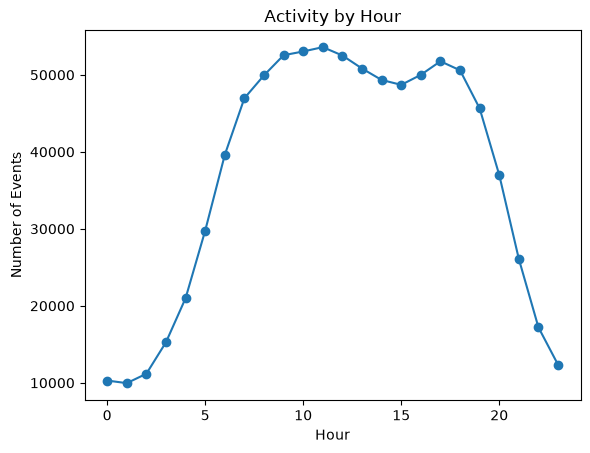

In [6]:
df["event_time"] = pd.to_datetime(df["event_time"])

df["hour"] = df["event_time"].dt.hour

hourly_activity = df["hour"].value_counts().sort_index()

hourly_activity.plot(kind="line", marker="o")

plt.title("Activity by Hour")
plt.xlabel("Hour")
plt.ylabel("Number of Events")
plt.show()

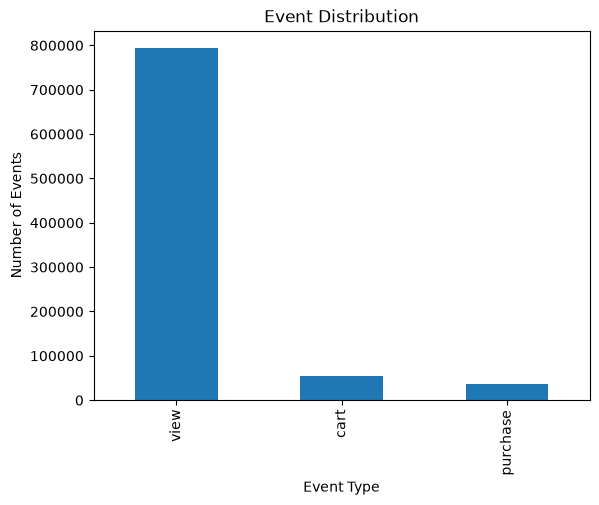

In [3]:
import matplotlib.pyplot as plt

event_counts = df["event_type"].value_counts()

event_counts.plot(kind="bar")

plt.title("Event Distribution")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.show()

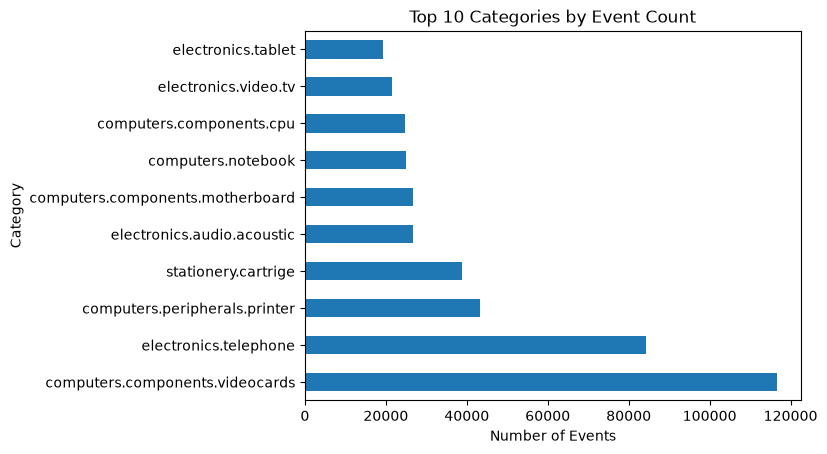

In [7]:
top_categories = df["category_code"].value_counts().head(10)

top_categories.plot(kind="barh")

plt.title("Top 10 Categories by Event Count")
plt.xlabel("Number of Events")
plt.ylabel("Category")
plt.show()

### Summary of EDA Findings

1. Data Cleaning: The dataset started with 885,129 rows. I found and removed 655 exact duplicate records, leaving 884,474 rows. There were missing values in category_code, brand, and user_session. I retained these missing values because they did not affect the main analysis, and dropping the entire rows would have removed otherwise valid event data.

2. Events: Most user actions are views which is 89.6%. Carts make up around 6%, and purchases make up about 4%.

3. Users: There are 407,283 unique users. Most users only have 1 or 2 interactions in the dataset.

4. Prices: Prices range from $0.22 to $64,771.06, while the median price is around $26. Most activity happens on products under $100.

5. Activity Hours: User activity peaks during the day between 09:00 and 13:00 UTC and drops to its lowest late at night between 00:00 and 03:00 UTC.

6. Top Categories: The most popular categories are computer parts and electronics, especially video cards, CPUs, and phones.